# LAB 12 — Artificial Neural Networks: The Perceptron
## Student Information
- **Name:** Haseeb Hassan
- **Roll No:** 023-24-0274
- **Section:** H
- **Date:** 11-18-2026

**Dataset:** Iris (sklearn built-in) · Use `random_state=42` everywhere · Write a 1–2 sentence interpretation under every plot and table.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_classification
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

np.random.seed(42)
iris = load_iris()
print("Iris loaded:", iris.data.shape, "| Classes:", iris.target_names)

Iris loaded: (150, 4) | Classes: ['setosa' 'versicolor' 'virginica']


## Part 1 — The Neuron From Scratch

### Task 1.1 — Weighted sum, step function and predict
Write `weighted_sum`, `step_function`, `predict`. Verify slide 16 (`predict([0.6,0.8],[2,3],-2)` → 1) and slide 17 (w=[1,−0.5], b=0.5; inputs [1,1],[2,1],[0,3] → 1, 1, 0).

In [2]:
# Task 1.1
def weighted_sum(w, x, b):
    return np.dot(w, x) + b

def step_function(z):
    return 1 if z >= 0 else 0

def predict(w, x, b):
    return step_function(weighted_sum(w, x, b))

# slide 16 check
print("Slide 16:", predict([0.6, 0.8], [2, 3], -2), "(expected 1)")

# slide 17 check
w17, b17 = [1, -0.5], 0.5
expected = [1, 1, 0]
for x, e in zip([[1, 1], [2, 1], [0, 3]], expected):
    print("Slide 17: input", x, "->", predict(w17, x, b17), "(expected", e, ")")


Slide 16: 1 (expected 1)
Slide 17: input [1, 1] -> 1 (expected 1 )
Slide 17: input [2, 1] -> 1 (expected 1 )
Slide 17: input [0, 3] -> 0 (expected 0 )


### Task 1.2 — One full epoch on the AND gate, by hand
AND: (0,0,0), (0,1,0), (1,0,0), (1,1,1). Start w=[0.2, −0.1], b=0, η=0.1. Print z, ŷ, e and the new w, b for each row; then the mistake count and "Converged!" / "Keep training.".

In [3]:
# Task 1.2
data = [(0, 0, 0), (0, 1, 0), (1, 0, 0), (1, 1, 1)]
w = np.array([0.2, -0.1])
b = 0.0
eta = 0.1
mistakes = 0

for x1, x2, y in data:
    x = np.array([x1, x2])
    z = np.dot(w, x) + b
    y_hat = 1 if z >= 0 else 0
    e = y - y_hat
    if e != 0:
        mistakes += 1
    w = w + eta * e * x
    b = b + eta * e
    print(f"x=({x1},{x2}) y={y} | z={z:.2f} y_hat={y_hat} e={e} | new w=[{w[0]:.2f}, {w[1]:.2f}] b={b:.2f}")

print("Final w =", np.round(w, 2), "b =", round(b, 2))
print("Mistakes in this epoch:", mistakes)
print("Converged!" if mistakes == 0 else "Keep training.")


x=(0,0) y=0 | z=0.00 y_hat=1 e=-1 | new w=[0.20, -0.10] b=-0.10
x=(0,1) y=0 | z=-0.20 y_hat=0 e=0 | new w=[0.20, -0.10] b=-0.10
x=(1,0) y=0 | z=0.10 y_hat=1 e=-1 | new w=[0.10, -0.10] b=-0.20
x=(1,1) y=1 | z=-0.20 y_hat=0 e=1 | new w=[0.20, 0.00] b=-0.10
Final w = [0.2 0. ] b = -0.1
Mistakes in this epoch: 3
Keep training.


## Part 2 — Train a Perceptron From Scratch

### Task 2.1 — Implement `train_perceptron`
`train_perceptron(X, y, eta=0.1, max_epochs=100)`: start from zeros, update on every mistake, record mistakes per epoch, stop after a zero-mistake epoch. Train on OR (y = [0,1,1,1]) and print w, b.

In [4]:
# Task 2.1
def train_perceptron(X, y, eta=0.1, max_epochs=100):
    X = np.array(X, dtype=float)
    y = np.array(y)
    w = np.zeros(X.shape[1])
    b = 0.0
    mistakes = []
    for epoch in range(max_epochs):
        errors = 0
        for xi, yi in zip(X, y):
            y_hat = predict(w, xi, b)
            e = yi - y_hat
            if e != 0:
                w = w + eta * e * xi
                b = b + eta * e
                errors += 1
        mistakes.append(errors)
        if errors == 0:
            break
    return w, b, mistakes

X_or = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_or = np.array([0, 1, 1, 1])

w_or, b_or, mistakes_or = train_perceptron(X_or, y_or)
print("OR gate -> w =", w_or, "b =", round(b_or, 2))
print("Mistakes per epoch:", mistakes_or)


OR gate -> w = [0.1 0.1] b = -0.1
Mistakes per epoch: [2, 2, 1, 0]


### Task 2.2 — Plot mistakes per epoch
Title "Perceptron training on OR gate", axes "Epoch" / "Mistakes"; mark the final epoch with a red dot.

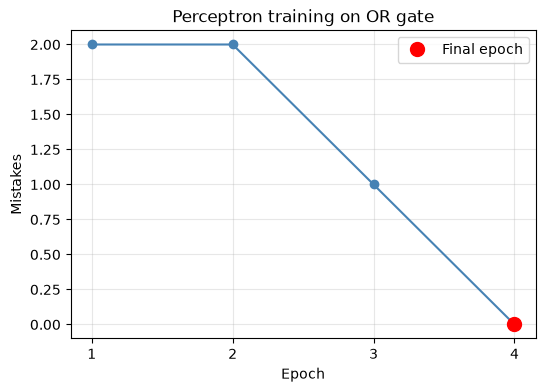

In [5]:
# Task 2.2
epochs = range(1, len(mistakes_or) + 1)
plt.figure(figsize=(6, 4))
plt.plot(epochs, mistakes_or, marker="o", color="steelblue")
plt.plot(len(mistakes_or), mistakes_or[-1], "ro", markersize=10, label="Final epoch")
plt.title("Perceptron training on OR gate")
plt.xlabel("Epoch")
plt.ylabel("Mistakes")
plt.xticks(list(epochs))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Interpretation:** The mistakes went 2, 2, 1, 0, so it learned the OR gate in 4 epochs. The red dot shows zero mistakes at the end, so it converged.

## Part 3 — The Decision Boundary

### Task 3.1 — Plot the OR gate with its boundary
Boundary: x₂ = −(w₁/w₂)x₁ − b/w₂ over `np.linspace(-0.5, 1.5, 100)`. Class 0 blue circles, class 1 red squares, boundary black dashed. Write a reusable `plot_boundary(ax, w, b)` that handles w₂ = 0.

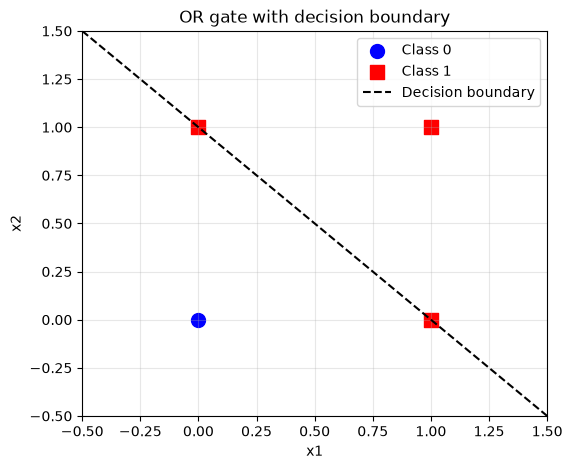

In [6]:
# Task 3.1
def plot_boundary(ax, w, b, xs=None, label="Decision boundary"):
    """Draw w1*x1 + w2*x2 + b = 0 on ax. Handles w2 = 0 (vertical line)."""
    if xs is None:
        xs = np.linspace(-0.5, 1.5, 100)
    w1, w2 = w[0], w[1]
    if w2 != 0:
        x2 = -(w1 / w2) * xs - b / w2
        ax.plot(xs, x2, "k--", label=label)
    elif w1 != 0:
        ax.axvline(-b / w1, color="k", linestyle="--", label=label)
    else:
        print("w1 and w2 are both 0, so there is no line to draw.")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(X_or[y_or == 0, 0], X_or[y_or == 0, 1], c="blue", marker="o", s=100, label="Class 0")
ax.scatter(X_or[y_or == 1, 0], X_or[y_or == 1, 1], c="red", marker="s", s=100, label="Class 1")
plot_boundary(ax, w_or, b_or, xs=np.linspace(-0.5, 1.5, 100))
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(-0.5, 1.5)
ax.set_title("OR gate with decision boundary")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.legend()
ax.grid(alpha=0.3)
plt.show()


**Interpretation:** The line is x2 = -x1 + 1 (w = [0.1, 0.1], b = -0.1). The side above and right of the line is where y_hat = 1, because z >= 0 there.

### Task 3.2 — With and without bias
Train both versions on X=[[1,0],[0,1],[2,1],[1,2]], y=[0,0,1,1]; plot the two boundaries side by side. Did the no-bias version converge?

With bias    : w = [0.1 0.1] b = -0.2 | epochs = 4 | final mistakes = 0
Without bias : w = [0.1 0. ] b = 0.0 | epochs = 100 | final mistakes = 2
No-bias version converged? False


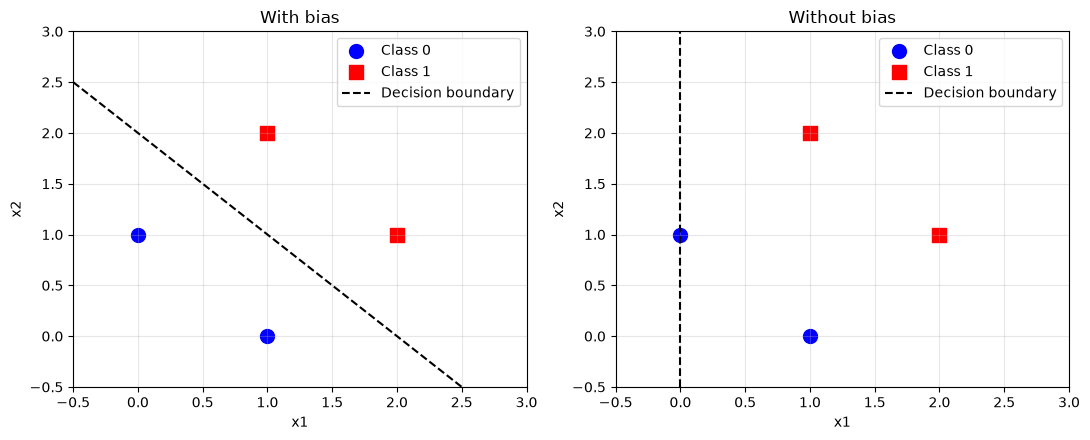

In [7]:
# Task 3.2
def train_perceptron_nobias(X, y, eta=0.1, max_epochs=100):
    X = np.array(X, dtype=float)
    y = np.array(y)
    w = np.zeros(X.shape[1])
    b = 0.0   # stays 0 and is never updated
    mistakes = []
    for epoch in range(max_epochs):
        errors = 0
        for xi, yi in zip(X, y):
            y_hat = predict(w, xi, b)
            e = yi - y_hat
            if e != 0:
                w = w + eta * e * xi   # only w is updated
                errors += 1
        mistakes.append(errors)
        if errors == 0:
            break
    return w, b, mistakes

X32 = np.array([[1, 0], [0, 1], [2, 1], [1, 2]])
y32 = np.array([0, 0, 1, 1])

w_b, b_b, m_b = train_perceptron(X32, y32)
w_nb, b_nb, m_nb = train_perceptron_nobias(X32, y32)

print("With bias    : w =", w_b, "b =", round(b_b, 2), "| epochs =", len(m_b), "| final mistakes =", m_b[-1])
print("Without bias : w =", w_nb, "b =", b_nb, "| epochs =", len(m_nb), "| final mistakes =", m_nb[-1])
print("No-bias version converged?", m_nb[-1] == 0)

xs32 = np.linspace(-0.5, 3, 100)
titles = ["With bias", "Without bias"]
params = [(w_b, b_b), (w_nb, b_nb)]
plt.figure(figsize=(11, 4.5))
for k in (1, 2):
    ax = plt.subplot(1, 2, k)
    ax.scatter(X32[y32 == 0, 0], X32[y32 == 0, 1], c="blue", marker="o", s=100, label="Class 0")
    ax.scatter(X32[y32 == 1, 0], X32[y32 == 1, 1], c="red", marker="s", s=100, label="Class 1")
    plot_boundary(ax, params[k - 1][0], params[k - 1][1], xs=xs32)
    ax.set_xlim(-0.5, 3)
    ax.set_ylim(-0.5, 3)
    ax.set_title(titles[k - 1])
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretation:** The version with bias converged in 4 epochs, but the no-bias version did not (still 2 mistakes after 100 epochs). Without bias the line has to pass through the origin, and no such line separates these points.

## Part 4 — The XOR Limitation

### Task 4.1 — Watch the perceptron fail
XOR: y = [0,1,1,0], `max_epochs=100`. Print final mistakes, w, b; plot mistakes per epoch and the boundary.

Epochs run: 100
Final mistake count: 4
Final w = [-0.1  0. ] b = 0.0
Did it ever reach zero mistakes? False


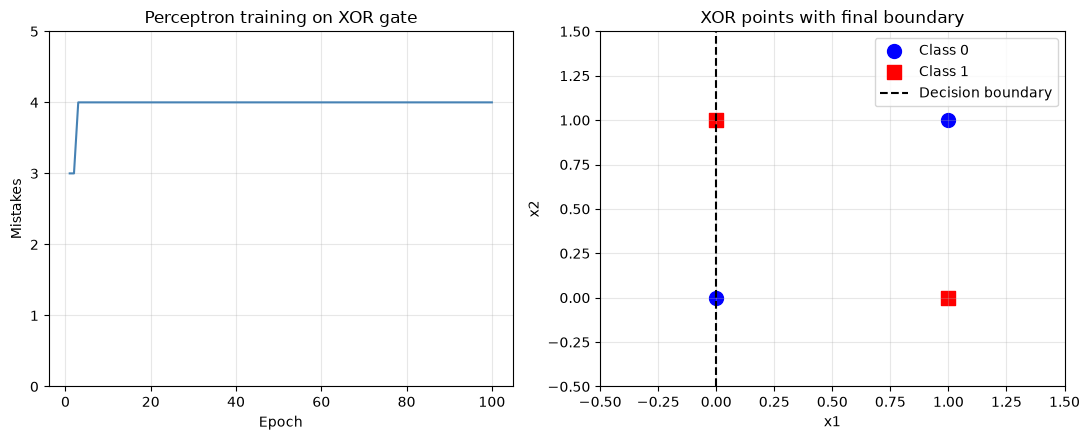

In [8]:
# Task 4.1
y_xor = np.array([0, 1, 1, 0])
w_x, b_x, m_x = train_perceptron(X_or, y_xor, max_epochs=100)

print("Epochs run:", len(m_x))
print("Final mistake count:", m_x[-1])
print("Final w =", w_x, "b =", round(b_x, 2))
print("Did it ever reach zero mistakes?", 0 in m_x)

plt.figure(figsize=(11, 4.5))

ax1 = plt.subplot(1, 2, 1)
ax1.plot(range(1, len(m_x) + 1), m_x, color="steelblue")
ax1.set_title("Perceptron training on XOR gate")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Mistakes")
ax1.set_ylim(0, 5)
ax1.grid(alpha=0.3)

ax2 = plt.subplot(1, 2, 2)
ax2.scatter(X_or[y_xor == 0, 0], X_or[y_xor == 0, 1], c="blue", marker="o", s=100, label="Class 0")
ax2.scatter(X_or[y_xor == 1, 0], X_or[y_xor == 1, 1], c="red", marker="s", s=100, label="Class 1")
plot_boundary(ax2, w_x, b_x, xs=np.linspace(-0.5, 1.5, 100))
ax2.set_xlim(-0.5, 1.5)
ax2.set_ylim(-0.5, 1.5)
ax2.set_title("XOR points with final boundary")
ax2.set_xlabel("x1")
ax2.set_ylabel("x2")
ax2.legend()
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretation:** No, it never reached zero mistakes and stayed at 3 or 4 for all 100 epochs. XOR is not linearly separable, so no single line can split the classes and the weights keep changing.

### Task 4.2 — Confirm no weight vector works
`check_xor(w, b)` returns True only if all four XOR constraints hold. Test 10,000 random (w₁, w₂, b) in [−5, 5].

In [9]:
# Task 4.2
def check_xor(w, b):
    return (np.dot(w, [0, 0]) + b < 0 and
            np.dot(w, [0, 1]) + b >= 0 and
            np.dot(w, [1, 0]) + b >= 0 and
            np.dot(w, [1, 1]) + b < 0)

np.random.seed(42)
W = np.random.uniform(-5, 5, (10000, 2))
B = np.random.uniform(-5, 5, 10000)

passed = [(W[i, 0], W[i, 1], B[i]) for i in range(10000) if check_xor(W[i], B[i])]
print("Triples tested: 10000")
print("Triples that pass:", len(passed))
if len(passed) == 0:
    print("No solution found")
else:
    print("First passing triple:", passed[0])


Triples tested: 10000
Triples that pass: 0
No solution found


## Part 5 — scikit-learn Perceptron on Iris

### Task 5.1 — Train and evaluate
Petal features (2, 3), Setosa vs rest; 70/30 stratified split; `Perceptron(random_state=42)`. Print accuracy, confusion matrix, report, `coef_`, `intercept_`.

In [10]:
# Task 5.1
X5 = iris.data[:, (2, 3)]
y5 = (iris.target == 0).astype(int)

X5_train, X5_test, y5_train, y5_test = train_test_split(
    X5, y5, test_size=0.3, random_state=42, stratify=y5)

clf = Perceptron(random_state=42)
clf.fit(X5_train, y5_train)
y5_pred = clf.predict(X5_test)

print("Accuracy:", accuracy_score(y5_test, y5_pred))
print("\nConfusion matrix:")
print(confusion_matrix(y5_test, y5_pred))
print("\nClassification report:")
print(classification_report(y5_test, y5_pred, target_names=["Rest", "Setosa"]))
print("coef_     :", clf.coef_)
print("intercept_:", clf.intercept_)


Accuracy: 1.0

Confusion matrix:
[[30  0]
 [ 0 15]]

Classification report:
              precision    recall  f1-score   support

        Rest       1.00      1.00      1.00        30
      Setosa       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

coef_     : [[-1.3 -2.2]]
intercept_: [4.]


**Interpretation:** Accuracy is 100%, all 30 rest and 15 setosa test samples are correct. coef_ = [-1.3, -2.2] are the weights w1 and w2, and intercept_ = 4.0 is the bias b.

### Task 5.2 — Visualise the learned boundary
Boundary from `coef_[0]`, `intercept_[0]`; test set coloured by class; misclassified points as red ×.

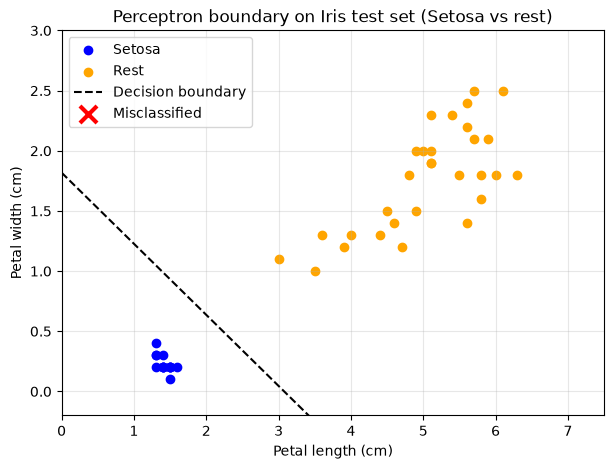

Misclassified test points: 0 out of 45


In [11]:
# Task 5.2
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X5_test[y5_test == 1, 0], X5_test[y5_test == 1, 1], c="blue", label="Setosa")
ax.scatter(X5_test[y5_test == 0, 0], X5_test[y5_test == 0, 1], c="orange", label="Rest")

plot_boundary(ax, clf.coef_[0], clf.intercept_[0], xs=np.linspace(0, 7.5, 100))

wrong = y5_pred != y5_test
ax.scatter(X5_test[wrong, 0], X5_test[wrong, 1], c="red", marker="x", s=150,
           linewidths=3, label="Misclassified", zorder=5)

ax.set_xlim(0, 7.5)
ax.set_ylim(-0.2, 3)
ax.set_title("Perceptron boundary on Iris test set (Setosa vs rest)")
ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Petal width (cm)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
print("Misclassified test points:", wrong.sum(), "out of", len(y5_test))


**Interpretation:** 0 out of 45 test points are misclassified, so there are no red crosses. Yes, the boundary is a straight line with setosa on one side and the rest on the other.

### Task 5.3 — Effect of learning rate
`eta0` = 0.001, 0.1, 10.0. Table of eta0 | accuracy | `n_iter_` | `coef_`. Do the predictions change? What does η do when training starts from w = 0?

In [12]:
# Task 5.3
results = []
print(f"{'eta0':<8}| {'accuracy':<9}| {'n_iter_':<8}| coef_")
print("-" * 60)
for eta0 in [0.001, 0.1, 10.0]:
    m = Perceptron(eta0=eta0, random_state=42)
    m.fit(X5_train, y5_train)
    acc = accuracy_score(y5_test, m.predict(X5_test))
    results.append(m)
    print(f"{eta0:<8}| {acc:<9.4f}| {m.n_iter_:<8}| {np.round(m.coef_[0], 4)}  (intercept {np.round(m.intercept_[0], 4)})")

print()
same = all(np.array_equal(results[0].predict(X5_test), r.predict(X5_test)) for r in results)
print("Predictions identical for all three eta0 values?", same)
print("coef ratio (eta0=0.1 / eta0=0.001):", np.round(results[1].coef_[0] / results[0].coef_[0], 2))
print("coef ratio (eta0=10 / eta0=0.1)   :", np.round(results[2].coef_[0] / results[1].coef_[0], 2))


eta0    | accuracy | n_iter_ | coef_
------------------------------------------------------------
0.001   | 1.0000   | 6       | [-0.0013 -0.0022]  (intercept 0.004)
0.1     | 1.0000   | 7       | [-0.13 -0.22]  (intercept 0.4)
10.0    | 1.0000   | 7       | [-13. -22.]  (intercept 40.0)

Predictions identical for all three eta0 values? True
coef ratio (eta0=0.1 / eta0=0.001): [100. 100.]
coef ratio (eta0=10 / eta0=0.1)   : [100. 100.]


**Interpretation:** No, the predictions do not change, all three models have accuracy 1.0. The coef_ vectors point the same way and just get 100 times bigger at each step of eta0, because training starts from w = 0 so eta only scales the weights.

## Part 6 — Multi-Class Classification

### Task 6.1 — All three Iris classes
All four features, `y = iris.target`, 70/30 stratified; `Perceptron(random_state=42, max_iter=1000)`. Print report, confusion matrix, `coef_.shape`. Which class is hardest?

In [13]:
# Task 6.1
X6 = iris.data
y6 = iris.target
X6_train, X6_test, y6_train, y6_test = train_test_split(
    X6, y6, test_size=0.3, random_state=42, stratify=y6)

clf6 = Perceptron(random_state=42, max_iter=1000)
clf6.fit(X6_train, y6_train)
y6_pred = clf6.predict(X6_test)

print("Classification report:")
print(classification_report(y6_test, y6_pred, target_names=iris.target_names, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y6_test, y6_pred))
print("\ncoef_.shape:", clf6.coef_.shape)


Classification report:
              precision    recall  f1-score   support

      setosa       0.52      1.00      0.68        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.67        45
   macro avg       0.48      0.67      0.55        45
weighted avg       0.48      0.67      0.55        45

Confusion matrix:
[[15  0  0]
 [14  0  1]
 [ 0  0 15]]

coef_.shape: (3, 4)


**Interpretation:** Accuracy is only about 0.67, and each row of coef_ (3 x 4) is one one-vs-rest perceptron for one class. Versicolor is the hardest class, 14 of its 15 test points were predicted as setosa because it sits between the other two classes.

### Task 6.2 — Perceptron vs Logistic Regression
`LogisticRegression(random_state=42, max_iter=200)` on the same split; side-by-side accuracy and macro-F1; why can it win (slide 32)?

In [14]:
# Task 6.2
lr = LogisticRegression(random_state=42, max_iter=200)
lr.fit(X6_train, y6_train)
y6_lr = lr.predict(X6_test)

acc_p = accuracy_score(y6_test, y6_pred)
acc_l = accuracy_score(y6_test, y6_lr)
f1_p = f1_score(y6_test, y6_pred, average="macro", zero_division=0)
f1_l = f1_score(y6_test, y6_lr, average="macro")

print(f"{'Model':<22}| {'Accuracy':<9}| Macro-F1")
print("-" * 45)
print(f"{'Perceptron':<22}| {acc_p:<9.4f}| {f1_p:.4f}")
print(f"{'Logistic Regression':<22}| {acc_l:<9.4f}| {f1_l:.4f}")


Model                 | Accuracy | Macro-F1
---------------------------------------------
Perceptron            | 0.6667   | 0.5499
Logistic Regression   | 0.9333   | 0.9333


**Interpretation:** Logistic regression is better (accuracy 0.9333 and macro-F1 0.9333, against 0.6667 and 0.5499 for the perceptron). Its sigmoid is smooth and the gradient is never zero so it keeps learning, but the step function only gives right or wrong.

## Part 7 — Graded Questions (5 marks)
Answer in the Markdown cells below, using your own numbers.

**Q1 [0.5 marks] — Manual update trace.** w = [0.5, −0.3], b = 0.2, η = 0.1, x = [1, 2], y = 0. Compute z and ŷ, then e, then the updated w₁, w₂ and b.

z = 0.5(1) + (-0.3)(2) + 0.2 = 0.1, so y_hat = 1 (wrong, since y = 0)  
e = y - y_hat = 0 - 1 = -1  
w1 = 0.5 + 0.1(-1)(1) = 0.4  
w2 = -0.3 + 0.1(-1)(2) = -0.5  
b = 0.2 + 0.1(-1) = 0.1

**Q2 [0.5 marks] — Boundary geometry.** After training on AND: w = [0.3, 0.2], b = −0.4. Write the boundary equation. Which side is (1, 1) on, and what is ŷ?

Boundary: 0.3 x1 + 0.2 x2 - 0.4 = 0 (or x2 = -1.5 x1 + 2).  
For (1, 1): z = 0.3 + 0.2 - 0.4 = 0.1, which is >= 0. So (1, 1) is on the positive side of the line and y_hat = 1.

**Q3 [1 mark] — XOR analysis.** (a) Show algebraically that the four XOR constraints cannot all hold. (b) Sketch XOR on x₁–x₂ axes (insert an image or a matplotlib plot) to show why no line separates it. (c) Name one architectural change that solves XOR.

(a) The four XOR constraints are:  
b < 0  
w2 + b >= 0  
w1 + b >= 0  
w1 + w2 + b < 0

Adding the 2nd and 3rd gives w1 + w2 + 2b >= 0, so w1 + w2 + b >= -b. Since b < 0, -b is positive, so w1 + w2 + b > 0. This contradicts the 4th constraint, so they cannot all hold.

(b) The plot is in the code cell below. The two class 0 points are opposite corners and the two class 1 points are the other corners, so any line leaves a point on the wrong side.

(c) Add a hidden layer (a multi-layer perceptron).

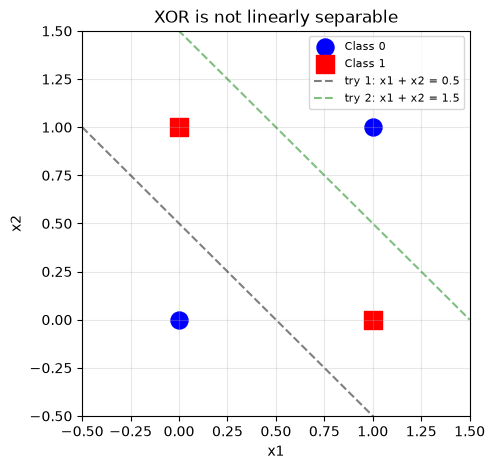

In [15]:
# Q3(b) XOR on x1-x2 axes
plt.figure(figsize=(5, 5))
plt.scatter([0, 1], [0, 1], c="blue", marker="o", s=150, label="Class 0")
plt.scatter([0, 1], [1, 0], c="red", marker="s", s=150, label="Class 1")
xs = np.linspace(-0.5, 1.5, 100)
plt.plot(xs, -xs + 0.5, "k--", alpha=0.5, label="try 1: x1 + x2 = 0.5")
plt.plot(xs, -xs + 1.5, "g--", alpha=0.5, label="try 2: x1 + x2 = 1.5")
plt.xlim(-0.5, 1.5)
plt.ylim(-0.5, 1.5)
plt.title("XOR is not linearly separable")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend(loc="upper right", fontsize=8)
plt.grid(alpha=0.3)
plt.show()


**Q4 [1.5 marks] — Iris extension.** Add sepal length (feature 0) so you use features (0, 2, 3). Retrain the Part 5 model; report accuracy and macro-F1. Does the extra feature help? Support your answer with numbers.

In [16]:
# Q4
X4 = iris.data[:, (0, 2, 3)]
y4 = (iris.target == 0).astype(int)
X4_train, X4_test, y4_train, y4_test = train_test_split(
    X4, y4, test_size=0.3, random_state=42, stratify=y4)

clf4 = Perceptron(random_state=42)
clf4.fit(X4_train, y4_train)
y4_pred = clf4.predict(X4_test)

acc_old = accuracy_score(y5_test, y5_pred)
f1_old = f1_score(y5_test, y5_pred, average="macro")
acc_new = accuracy_score(y4_test, y4_pred)
f1_new = f1_score(y4_test, y4_pred, average="macro")

print(f"{'Features':<18}| {'Accuracy':<9}| Macro-F1")
print("-" * 40)
print(f"{'(2, 3)':<18}| {acc_old:<9.4f}| {f1_old:.4f}")
print(f"{'(0, 2, 3)':<18}| {acc_new:<9.4f}| {f1_new:.4f}")
print("\nConfusion matrix with (0, 2, 3):")
print(confusion_matrix(y4_test, y4_pred))
print("coef_ =", clf4.coef_, "intercept_ =", clf4.intercept_)


Features          | Accuracy | Macro-F1
----------------------------------------
(2, 3)            | 1.0000   | 1.0000
(0, 2, 3)         | 1.0000   | 1.0000

Confusion matrix with (0, 2, 3):
[[30  0]
 [ 0 15]]
coef_ = [[ 4.5 -8.7 -4.1]] intercept_ = [2.]


With features (2, 3) accuracy and macro-F1 were both 1.0, and with (0, 2, 3) they are still both 1.0. So the extra feature does not help, because setosa vs rest was already perfectly separable using the petal features.

**Q5 [1.5 marks] — Synthetic data.** `make_classification(n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=42)`, 70/30 split. Train your hand-built perceptron and sklearn's. Compare accuracy, epochs, final w and b; plot both boundaries side by side.

Model         | Test acc | Epochs | w, b
---------------------------------------------------------------------------
Hand-built    | 0.8167   | 100    | w=[ 0.307 -0.256] b=0.200
sklearn       | 0.6667   | 6      | w=[2.281 0.58 ] b=2.000
Hand-built last epoch mistakes: 33


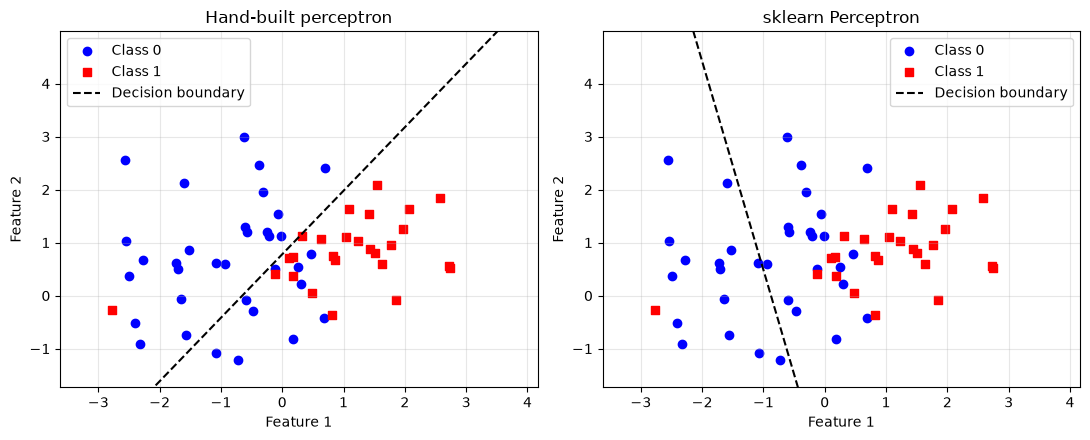

In [17]:
# Q5
Xs, ys = make_classification(n_samples=200, n_features=2, n_redundant=0,
                             n_clusters_per_class=1, random_state=42)
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    Xs, ys, test_size=0.3, random_state=42)

# hand-built perceptron
w_h, b_h, m_h = train_perceptron(Xs_train, ys_train, eta=0.1, max_epochs=100)
pred_h = np.array([predict(w_h, xi, b_h) for xi in Xs_test])
acc_h = accuracy_score(ys_test, pred_h)

# sklearn perceptron
sk = Perceptron(random_state=42)
sk.fit(Xs_train, ys_train)
pred_s = sk.predict(Xs_test)
acc_s = accuracy_score(ys_test, pred_s)

print(f"{'Model':<14}| {'Test acc':<9}| {'Epochs':<7}| w, b")
print("-" * 75)
print(f"{'Hand-built':<14}| {acc_h:<9.4f}| {len(m_h):<7}| w={np.round(w_h, 3)} b={b_h:.3f}")
print(f"{'sklearn':<14}| {acc_s:<9.4f}| {sk.n_iter_:<7}| w={np.round(sk.coef_[0], 3)} b={sk.intercept_[0]:.3f}")
print("Hand-built last epoch mistakes:", m_h[-1])

xs_range = np.linspace(Xs[:, 0].min() - 0.5, Xs[:, 0].max() + 0.5, 100)
plt.figure(figsize=(11, 4.5))
for k, (name, w_, b_, pred) in enumerate([("Hand-built perceptron", w_h, b_h, pred_h),
                                          ("sklearn Perceptron", sk.coef_[0], sk.intercept_[0], pred_s)], start=1):
    ax = plt.subplot(1, 2, k)
    ax.scatter(Xs_test[ys_test == 0, 0], Xs_test[ys_test == 0, 1], c="blue", marker="o", label="Class 0")
    ax.scatter(Xs_test[ys_test == 1, 0], Xs_test[ys_test == 1, 1], c="red", marker="s", label="Class 1")
    plot_boundary(ax, w_, b_, xs=xs_range)
    ax.set_xlim(Xs[:, 0].min() - 0.5, Xs[:, 0].max() + 0.5)
    ax.set_ylim(Xs[:, 1].min() - 0.5, Xs[:, 1].max() + 0.5)
    ax.set_title(name)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Hand-built: accuracy 0.8167, 100 epochs (33 mistakes in the last one), w = [0.307, -0.256], b = 0.200.  
sklearn: accuracy 0.6667, 6 epochs, w = [2.281, 0.58], b = 2.0.

The data is not linearly separable, so neither one converges. The sklearn line is too far left and gets 19 of the 34 class 0 test points wrong, compared to 10 for the hand-built one.